<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week10_1109/MNIST_MobileNet_shape.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST → MobileNet: 2D CNN 입력 shape 변환 실습


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input

tf.keras.utils.set_random_seed(42)
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 5
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()
print("원본 학습:", train_images.shape)
print("원본 테스트:", test_images.shape)

train_images = train_images[..., np.newaxis]
test_images = test_images[..., np.newaxis]
print("채널 추가 후 학습:", train_images.shape)
print("채널 추가 후 테스트:", test_images.shape)
print("픽셀 범위:", train_images.min(), "~", train_images.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
원본 학습: (60000, 28, 28)
원본 테스트: (10000, 28, 28)
채널 추가 후 학습: (60000, 28, 28, 1)
채널 추가 후 테스트: (10000, 28, 28, 1)
픽셀 범위: 0 ~ 255


흑백: (28, 28, 1)
resize: (128, 128, 1)
RGB 복제: (128, 128, 3)
배치 축 추가: (1, 128, 128, 3)
전처리: (1, 128, 128, 3)
전처리 값 범위: -1.0 ~ 0.987973


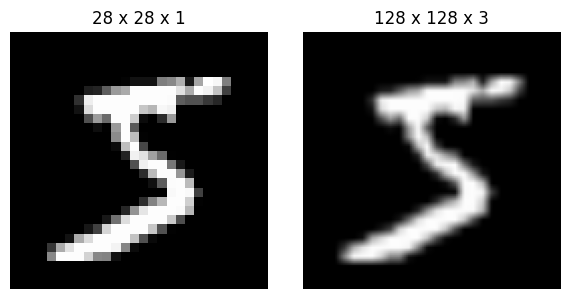

In [3]:
one_gray = train_images[0]                                  # (28, 28, 1)
one_resized = tf.image.resize(one_gray, (IMG_SIZE, IMG_SIZE)) # (128, 128, 1)
one_rgb = tf.image.grayscale_to_rgb(one_resized)             # (128, 128, 3)
one_batch = np.expand_dims(one_rgb.numpy(), axis=0)          # (1, 128, 128, 3)
one_preprocessed = preprocess_input(one_batch.copy())        # shape 유지, 값만 변환

print("흑백:", one_gray.shape)
print("resize:", one_resized.shape)
print("RGB 복제:", one_rgb.shape)
print("배치 축 추가:", one_batch.shape)
print("전처리:", one_preprocessed.shape)
print("전처리 값 범위:", one_preprocessed.min(), "~", one_preprocessed.max())

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(one_gray[..., 0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("28 x 28 x 1")
axes[1].imshow(one_rgb.numpy().astype("uint8"))
axes[1].set_title("128 x 128 x 3")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(train_images))
train_indices, val_indices = indices[:-6000], indices[-6000:]

train_x, train_y = train_images[train_indices], train_labels[train_indices]
val_x, val_y = train_images[val_indices], train_labels[val_indices]

def prepare_batch(images, labels):
    images = tf.cast(images, tf.float32)
    images = tf.image.resize(images, (IMG_SIZE, IMG_SIZE))
    images = tf.image.grayscale_to_rgb(images)
    images = preprocess_input(images)
    return images, labels

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(min(len(images), 10000), seed=42)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_x, train_y, training=True)
val_ds = make_dataset(val_x, val_y)
test_ds = make_dataset(test_images, test_labels)

batch_images, batch_labels = next(iter(train_ds))
print("モデルに渡す画像:", batch_images.shape)
print("ラベル:", batch_labels.shape)
print("学習 / 検証 / テスト:", len(train_x), len(val_x), len(test_images))

tf.debugging.assert_shapes([(batch_images, (None, IMG_SIZE, IMG_SIZE, 3))])
tf.debugging.assert_near(batch_images[..., 0], batch_images[..., 1])
tf.debugging.assert_near(batch_images[..., 1], batch_images[..., 2])
tf.debugging.assert_greater_equal(tf.reduce_min(batch_images), -1.0)
tf.debugging.assert_less_equal(tf.reduce_max(batch_images), 1.0)


モデルに渡す画像: (32, 128, 128, 3)
ラベル: (32,)
学習 / 検証 / テスト: 54000 6000 10000


In [5]:
base_model = MobileNet(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="rgb_images")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dense(1024, activation="relu", name="dense_1024_a")(x)
x = layers.Dense(1024, activation="relu", name="dense_1024_b")(x)
x = layers.Dense(512, activation="relu", name="dense_512")(x)
outputs = layers.Dense(10, activation="softmax", name="digit_probabilities")(x)
model = models.Model(inputs, outputs, name="mnist_mobilenet")

print("MobileNet 입력:", base_model.input_shape)
print("MobileNet 특징 출력:", base_model.output_shape)
print("전체 모델 출력:", model.output_shape)
model.summary()


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNet 입력: (None, 128, 128, 3)
MobileNet 특징 출력: (None, 4, 4, 1024)
전체 모델 출력: (None, 10)


Model: "mnist_mobilenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_images (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_128 (Functional) │ (None, 4, 4, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1024_a (Dense)            │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1024_b (Dense)            │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit_probabilities (Dense)     │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,857,994 (22.35 MB)

 Trainable params: 2,629,130 (10.03 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [6]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 58s 25ms/step - accuracy: 0.9551 - loss: 0.1476 - val_accuracy: 0.9610 - val_loss: 0.1365
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 53s 15ms/step - accuracy: 0.9749 - loss: 0.0847 - val_accuracy: 0.9753 - val_loss: 0.0912
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9807 - loss: 0.0678 - val_accuracy: 0.9763 - val_loss: 0.0948
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.9844 - loss: 0.0530 - val_accuracy: 0.9828 - val_loss: 0.0713
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.9870 - loss: 0.0462 - val_accuracy: 0.9737 - val_loss: 0.0902


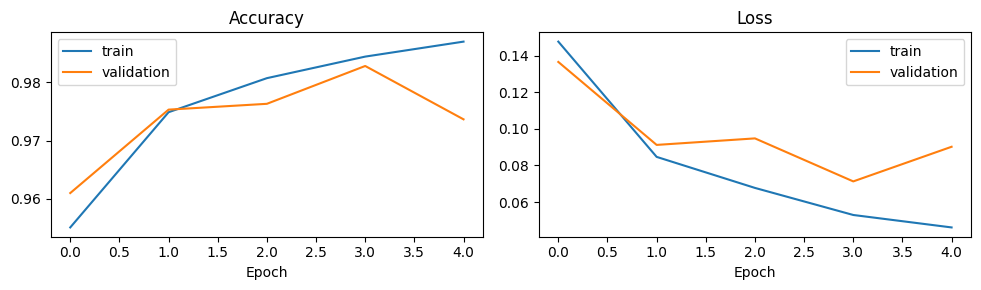

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set(title="Accuracy", xlabel="Epoch")
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set(title="Loss", xlabel="Epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


In [8]:
RUN_FINE_TUNING = False
if RUN_FINE_TUNING:
    base_model.trainable = True
    for i, layer in enumerate(base_model.layers):
        layer.trainable = (i >= 20) and not isinstance(layer, layers.BatchNormalization)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    history_finetune = model.fit(train_ds, validation_data=val_ds, epochs=2)
else:
    print("미세조정 생략: MobileNet 고정 + 새 분류층 학습 결과를 평가합니다.")


미세조정 생략: MobileNet 고정 + 새 분류층 학습 결과를 평가합니다.


In [9]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"테스트 정확도: {test_acc:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9734 - loss: 0.1064
테스트 정확도: 0.9734


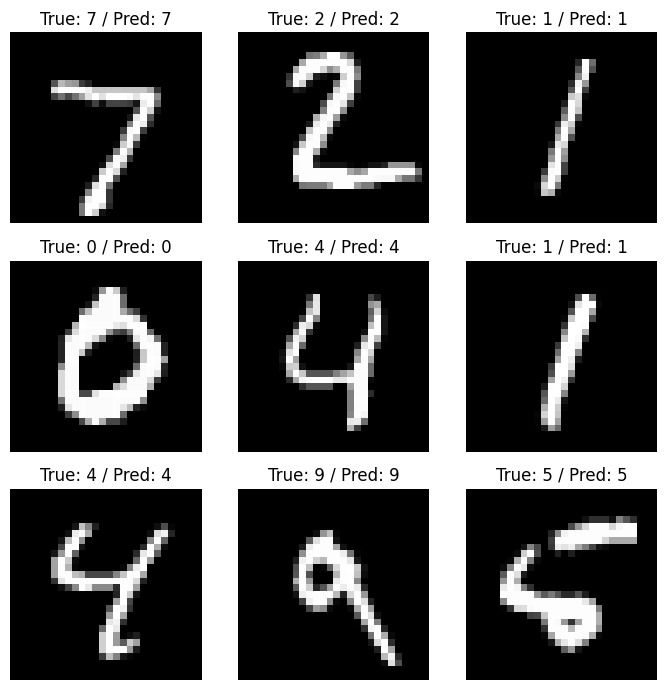

In [10]:
probabilities = model.predict(test_ds.take(1), verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(test_images[i, ..., 0], cmap="gray")
    ax.set_title(f"True: {test_labels[i]} / Pred: {predicted_labels[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 원본 코드에서 바뀐 곳

1. 데이터 로드: MNIST 사용은 그대로이고 채널 축만 추가합니다.
2. 정규화: 기존 `/ 255.0` 대신 MobileNet의 `preprocess_input`을 사용합니다.
3. shape: 28×28×1을 resize와 RGB 복제로 128×128×3으로 바꿉니다.
4. 모델: 직접 만든 Conv2D 블록 대신 사전 학습 MobileNet과 사진의 Dense 분류기를 연결합니다.
5. 학습/평가: 큰 이미지를 메모리에 전부 만들지 않도록 Dataset 배치로 전달합니다.